# DTLD

> Per-frame RGB scenes of transparent containers with strong reflections/refractions (robustness / domain generalization stress-test).

**GT available (per object):**
- Container/object identity (`obj_id`) + visibility (`visib_fract`, and bboxes when present)
- Liquid height in mm (`liquid_h`) and liquid label points (`liquid_label`) when annotated
- Visible object mask (`mask_visib/*.png`), and optional depth frames when available

In [2]:
from __future__ import annotations

import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Make repo dataset loaders importable in notebooks.
sys.path.append(str(Path("..") / "src"))
from datasets.dtld import DTLDDataset

ROOT = Path("..") / "data" / "DTLD_dataset"
assert ROOT.exists(), f"Dataset root not found: {ROOT}"

dtld = DTLDDataset(ROOT, rgb_only=False)

scene_dirs = sorted([p for p in ROOT.iterdir() if p.is_dir()])
scene_ids = [p.name for p in scene_dirs]

print(f"Dataset root: {ROOT}")
print(f"Total scenes: {len(scene_dirs)}")
print(f"Total object-entries (from scene_gt_liquid): {len(dtld):,}")
print("Scene IDs:", ", ".join(scene_ids))

Dataset root: ../data/DTLD_dataset
Total scenes: 14
Total object-entries (from scene_gt_liquid): 85,167
Scene IDs: 000000, 000001, 000002, 000003, 000004, 000005, 000006, 000007, 000008, 000009, 000010, 000011, 000012, 000013


## Capability audit across scenes

DTLD has a mix of:

- **Core modalities** (present in all scenes): RGB, depth, mask, mask_visib, camera + object annotations.
- **Liquid-specific labels** (present in a subset): `scene_gt_liquid`, `liquid_label`, `scene_gtori`.
- **Prediction artifacts** (in some scene folders): converted curves and scalar liquid-height predictions.

File/modality availability across scenes:
- depth                14/14 scenes
- liquid_label         10/14 scenes
- mask                 14/14 scenes
- mask_visib           14/14 scenes
- mask_visib_liquid     1/14 scenes
- pred_liquid_h.json    1/14 scenes
- preds_converted.json  1/14 scenes
- rgb                  14/14 scenes
- scene_camera.json    14/14 scenes
- scene_gt.json        14/14 scenes
- scene_gt_info.json   14/14 scenes
- scene_gt_liquid.json 11/14 scenes
- scene_gtori.json     11/14 scenes


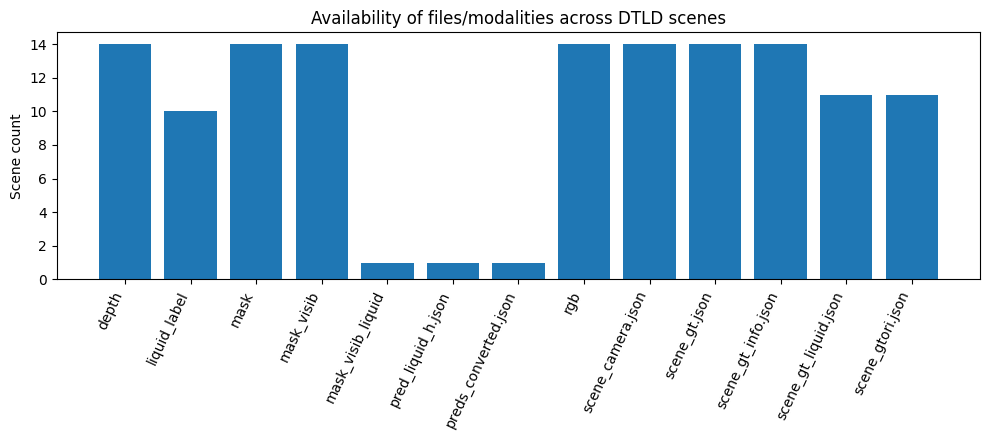

In [3]:
file_presence = Counter()
scene_file_sets = {}

for scene in scene_dirs:
    names = {p.name for p in scene.iterdir()}
    scene_file_sets[scene.name] = names
    for n in names:
        file_presence[n] += 1

print('File/modality availability across scenes:')
for name, count in sorted(file_presence.items()):
    print(f'- {name:<20} {count:>2}/{len(scene_dirs)} scenes')

labels = sorted(file_presence.keys())
counts = [file_presence[k] for k in labels]

plt.figure(figsize=(10, 4.5))
plt.bar(labels, counts)
plt.xticks(rotation=65, ha='right')
plt.ylabel('Scene count')
plt.title('Availability of files/modalities across DTLD scenes')
plt.tight_layout()
plt.show()

## Annotation schema and dataset statistics

From dataset inspection:

- `scene_camera.json` stores camera intrinsics/extrinsics per frame (`cam_K`, `cam_R_w2c`, `cam_t_w2c`, `depth_scale`).
- `scene_gt.json` stores per-object pose with keys like `obj_id`, `cam_R_m2c`, `cam_t_m2c`.
- `scene_gt_info.json` provides object visibility and boxes (`bbox_obj`, `bbox_visib`, `visib_fract`, pixel counts).
- `scene_gt_liquid.json` extends object entries with `liquid_h` and point labels (`liquid_label`).

Total frames across scenes (frames with liquid annotations): 21,305
Total object entries (scene_gt_liquid): 85,167
Unique object IDs (obj_id): 4

Top object IDs by frequency:
- obj_id=17: 21,305
- obj_id=16: 21,305
- obj_id=19: 21,305
- obj_id=15: 21,252

Visibility fraction summary:
- min: 0.000
- median: 1.000
- max: 1.000

Liquid height summary (from scene_gt_liquid):
- min: 14.70
- median: 45.10
- max: 96.00


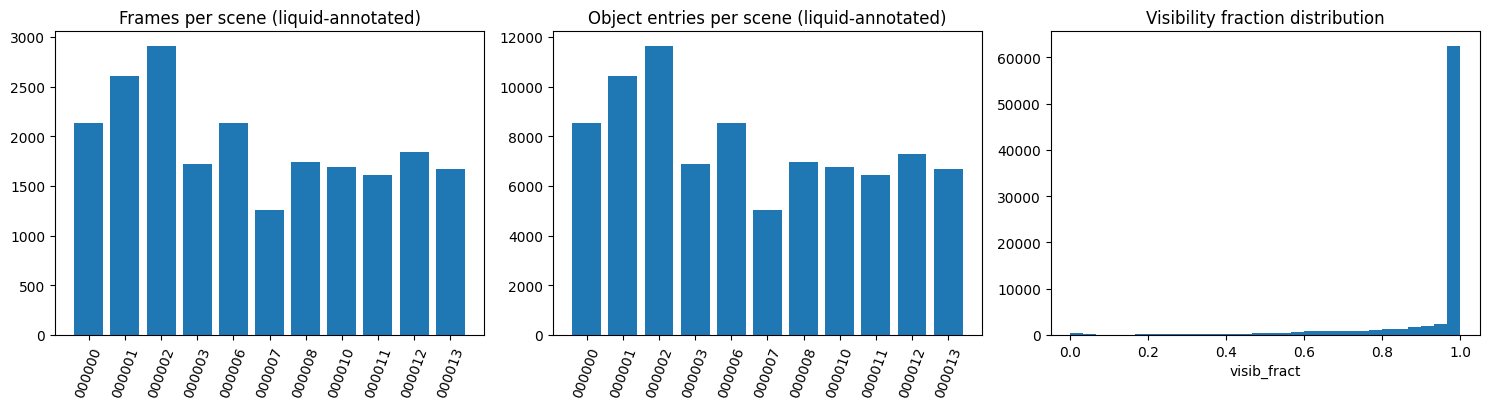

In [4]:
from collections import Counter, defaultdict

scene_frame_sets: dict[str, set[int]] = defaultdict(set)
scene_obj_counts: Counter[str] = Counter()
obj_id_counter: Counter[int] = Counter()
visib_fracts: list[float] = []
liquid_h_values: list[float] = []

for sample in dtld:
    scene_id = str(sample.get("scene_id", ""))
    frame_id = int(sample.get("frame_id", -1))
    scene_frame_sets[scene_id].add(frame_id)
    scene_obj_counts[scene_id] += 1

    obj_id = sample.get("obj_id")
    if isinstance(obj_id, int):
        obj_id_counter[obj_id] += 1

    vf = sample.get("visib_fract")
    if isinstance(vf, (int, float)):
        visib_fracts.append(float(vf))

    lh = sample.get("liquid_h")
    if isinstance(lh, (int, float)):
        liquid_h_values.append(float(lh))

scene_frame_counts = {k: len(v) for k, v in scene_frame_sets.items()}
scene_obj_counts_dict = dict(scene_obj_counts)

total_frames = sum(scene_frame_counts.values())
total_objects = sum(scene_obj_counts_dict.values())

print(f"Total frames across scenes (frames with liquid annotations): {total_frames:,}")
print(f"Total object entries (scene_gt_liquid): {total_objects:,}")
print(f"Unique object IDs (obj_id): {len(obj_id_counter)}")

print("\nTop object IDs by frequency:")
for obj_id, cnt in obj_id_counter.most_common(10):
    print(f"- obj_id={obj_id}: {cnt:,}")

if visib_fracts:
    arr = np.array(visib_fracts)
    print("\nVisibility fraction summary:")
    print(f"- min: {arr.min():.3f}")
    print(f"- median: {np.median(arr):.3f}")
    print(f"- max: {arr.max():.3f}")

if liquid_h_values:
    arr_h = np.array(liquid_h_values)
    print("\nLiquid height summary (from scene_gt_liquid):")
    print(f"- min: {arr_h.min():.2f}")
    print(f"- median: {np.median(arr_h):.2f}")
    print(f"- max: {arr_h.max():.2f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].bar(list(scene_frame_counts.keys()), list(scene_frame_counts.values()))
axes[0].set_title("Frames per scene (liquid-annotated)")
axes[0].tick_params(axis="x", rotation=70)

axes[1].bar(list(scene_obj_counts_dict.keys()), list(scene_obj_counts_dict.values()))
axes[1].set_title("Object entries per scene (liquid-annotated)")
axes[1].tick_params(axis="x", rotation=70)

axes[2].hist(visib_fracts, bins=30)
axes[2].set_title("Visibility fraction distribution")
axes[2].set_xlabel("visib_fract")

plt.tight_layout()
plt.show()

## Multi-modal frame panel

The next cell shows all available visual modalities for a selected frame:

- RGB
- depth
- mask
- visible mask
- liquid-specific masks when present (`liquid_label`, `mask_visib_liquid`)

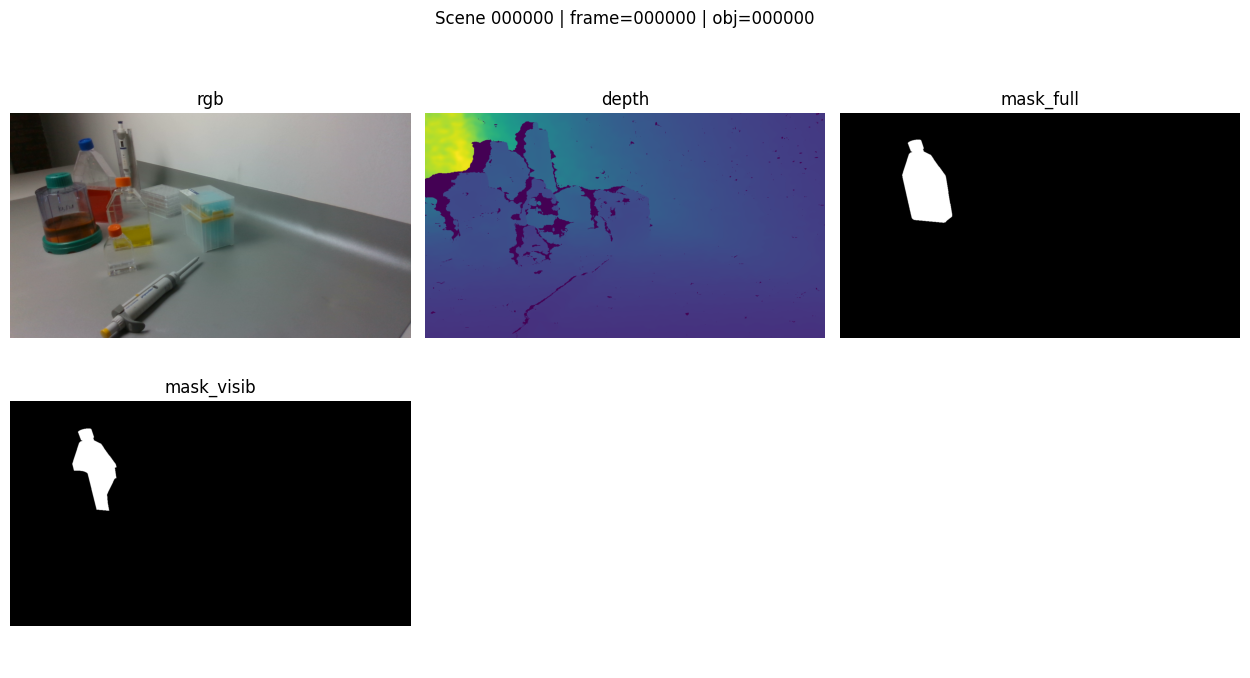

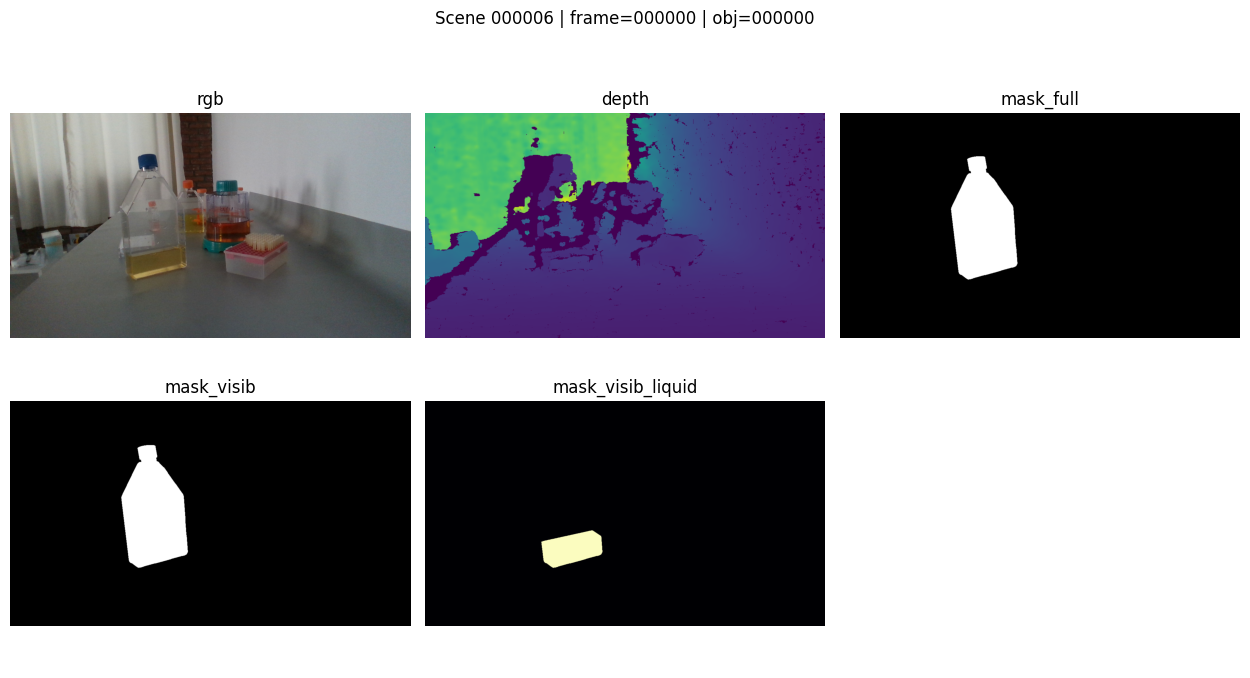

In [5]:
def read_img(path: Path):
    if not isinstance(path, Path) or not path.exists():
        return None
    return plt.imread(path)


try:
    _entries = dtld._entries  # type: ignore[attr-defined]
    entry_to_idx = {(sid, int(fid), int(oid)): i for i, (sid, fid, oid) in enumerate(_entries)}
except Exception:
    entry_to_idx = {}


def show_modalities(scene_id: str, frame_idx: int = 0, obj_idx: int = 0):
    idx = entry_to_idx.get((scene_id, int(frame_idx), int(obj_idx)))
    if idx is None:
        print(f"No sample found for scene={scene_id}, frame={frame_idx}, obj={obj_idx}")
        return

    sample = dtld[int(idx)]
    items = [
        ("rgb", sample.get("rgb_image"), None),
        ("depth", sample.get("depth_image"), "viridis"),
        ("mask_full", sample.get("mask_full_image"), "gray"),
        ("mask_visib", sample.get("mask_visib_image"), "gray"),
        ("liquid_label", sample.get("liquid_label_image"), "magma"),
        ("mask_visib_liquid", sample.get("mask_visib_liquid_image"), "magma"),
    ]

    valid_items = []
    for label, path, cmap in items:
        if isinstance(path, Path):
            img = read_img(path)
            if img is not None:
                valid_items.append((label, img, cmap, path))

    if not valid_items:
        print(f"No images found for scene={scene_id}, frame={frame_idx}, obj={obj_idx}")
        return

    cols = 3
    rows = int(np.ceil(len(valid_items) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4.2 * cols, 3.3 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, (label, img, cmap, path) in zip(axes, valid_items):
        if img.ndim == 2:
            ax.imshow(img, cmap=cmap)
        else:
            ax.imshow(img)
        ax.set_title(label)
        ax.axis("off")

    for ax in axes[len(valid_items) :]:
        ax.axis("off")

    fig.suptitle(f"Scene {scene_id} | frame={int(frame_idx):06d} | obj={int(obj_idx):06d}", y=1.02)
    plt.tight_layout()
    plt.show()


# Representative scenes: one core-only scene + one with richer liquid/prediction artifacts
show_modalities("000000", frame_idx=0, obj_idx=0)
show_modalities("000006", frame_idx=0, obj_idx=0)

## Overlaying annotations on RGB

This view overlays:

- `bbox_obj` and `bbox_visib` from `scene_gt_info.json`,
- and liquid keypoints (`A, B, C, D`) from `scene_gt_liquid.json` when available.

Using scene=000000, frame=0


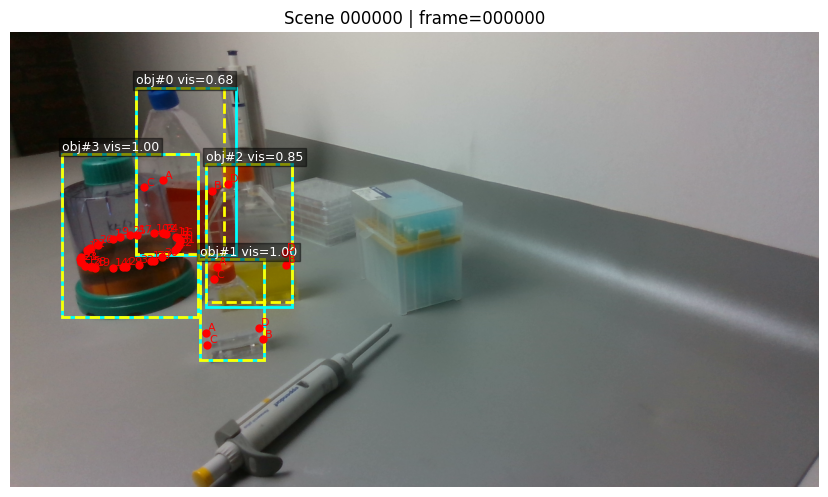

In [6]:
def overlay_annotations(scene_id: str, frame_idx: int = 0, obj_limit: int = 4):
    # Gather all indices for this frame without scanning every sample dict repeatedly.
    indices = [i for i, (sid, fid, _) in enumerate(dtld._entries) if sid == scene_id and int(fid) == int(frame_idx)]  # type: ignore[attr-defined]
    if not indices:
        print(f"No liquid-annotated objects found for scene={scene_id}, frame={frame_idx}")
        return

    indices = indices[: int(obj_limit)]
    frame_samples = [dtld[int(i)] for i in indices]
    frame_samples = sorted(frame_samples, key=lambda x: int(x.get("obj_idx", 0)))

    rgb_path = frame_samples[0].get("rgb_image")
    if not isinstance(rgb_path, Path):
        print("RGB image missing in sample")
        return
    rgb = read_img(rgb_path)
    if rgb is None:
        print(f"RGB image missing: {rgb_path}")
        return

    fig, ax = plt.subplots(figsize=(8.5, 5))
    ax.imshow(rgb)
    ax.set_title(f"Scene {scene_id} | frame={int(frame_idx):06d}")

    for s in frame_samples:
        bbox_obj = s.get("bbox_obj", [])
        bbox_vis = s.get("bbox_visib", [])
        if isinstance(bbox_obj, list) and len(bbox_obj) == 4:
            x, y, w, h = bbox_obj
            rect = plt.Rectangle((x, y), w, h, fill=False, linewidth=2, color="cyan")
            ax.add_patch(rect)
        if isinstance(bbox_vis, list) and len(bbox_vis) == 4:
            x, y, w, h = bbox_vis
            rect = plt.Rectangle((x, y), w, h, fill=False, linewidth=2, linestyle="--", color="yellow")
            ax.add_patch(rect)

        vis = s.get("visib_fract")
        vis_str = f"{float(vis):.2f}" if isinstance(vis, (int, float)) else "?"
        text_x = bbox_obj[0] if isinstance(bbox_obj, list) and len(bbox_obj) == 4 else 5
        text_y = (bbox_obj[1] - 6) if isinstance(bbox_obj, list) and len(bbox_obj) == 4 else 20
        ax.text(
            text_x,
            text_y,
            f"obj#{int(s.get('obj_idx', 0))} vis={vis_str}",
            color="white",
            fontsize=9,
            bbox=dict(facecolor="black", alpha=0.45, pad=2),
        )

        lbl = s.get("liquid_label")
        if isinstance(lbl, dict):
            for k, pt in lbl.items():
                if isinstance(pt, list) and len(pt) == 2:
                    ax.scatter(pt[0], pt[1], s=25, color="red")
                    ax.text(pt[0] + 3, pt[1] - 3, f"{k}", color="red", fontsize=8)

    ax.axis("off")
    plt.tight_layout()
    plt.show()


chosen_scene, chosen_frame = None, None
for i in range(len(dtld)):
    s = dtld[i]
    lbl = s.get("liquid_label")
    if isinstance(lbl, dict) and lbl:
        chosen_scene = str(s.get("scene_id"))
        chosen_frame = int(s.get("frame_id", 0))
        break

if chosen_scene is None:
    chosen_scene, chosen_frame = "000000", 0

print(f"Using scene={chosen_scene}, frame={chosen_frame}")
overlay_annotations(chosen_scene, chosen_frame, obj_limit=4)

## Optional prediction artifacts

Some scene folders include model outputs such as:

- `pred_liquid_h.json`: scalar height predictions per mask path,
- `preds_converted.json`: polyline/curve predictions.

The cell below summarizes and visualizes these when available.

Prediction scene: 000006
- pred_liquid_h entries: 46
- preds_converted entries: 8,370


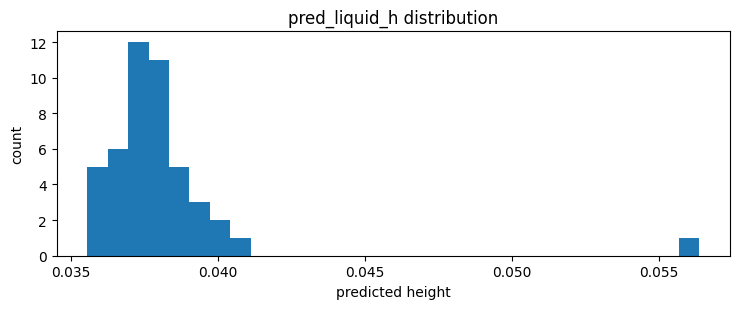

In [7]:
import json

def load_json(path: Path):
    try:
        return json.loads(path.read_text(encoding="utf-8"))
    except Exception:
        return None

pred_scene = None
for s in scene_dirs:
    if (s / "pred_liquid_h.json").exists() and (s / "preds_converted.json").exists():
        pred_scene = s
        break

if pred_scene is None:
    print("No scene with both prediction files found.")
else:
    print(f"Prediction scene: {pred_scene.name}")

    pred_h = load_json(pred_scene / "pred_liquid_h.json") or {}
    pred_curve = load_json(pred_scene / "preds_converted.json") or {}

    print(f"- pred_liquid_h entries: {len(pred_h):,}")
    print(f"- preds_converted entries: {len(pred_curve):,}")

    if pred_h:
        vals = np.array(list(pred_h.values()), dtype=float)
        plt.figure(figsize=(7.5, 3.2))
        plt.hist(vals, bins=30)
        plt.title("pred_liquid_h distribution")
        plt.xlabel("predicted height")
        plt.ylabel("count")
        plt.tight_layout()
        plt.show()

## Takeaways

- DTLD is a **multi-scene, multi-frame, multi-modal** dataset with strong core coverage (RGB/depth/masks/poses).
- It includes **instance-level visibility and geometry metadata** suitable for perception/pose tasks.
- A subset of scenes adds **liquid-specific supervision** (`liquid_h`, labeled liquid points, liquid masks).
- Some scenes also store **prediction artifacts**, enabling error analysis and qualitative benchmarking.

This notebook can serve as a reusable dataset presentation before model development.